# Rough work: building up to the MLP language model

Scratch notebook that follows Karpathy's *makemore* part 2. It builds the Bengio-style MLP step by step with tiny tensors, runs a learning-rate sweep, then trains a first full model. The cleaned-up version with momentum is in `../main/`.

Code and outputs are as they were in Colab. Notes are added in markdown cells only.

In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
!wget https://raw.githubusercontent.com/karpathy/makemore/master/names.txt
words = open('names.txt', 'r').read().splitlines()
words[:8]

--2026-09-09 21:25:56--  https://raw.githubusercontent.com/karpathy/makemore/master/names.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 228145 (223K) [text/plain]
Saving to: ‘names.txt’

names.txt           100%[===================>] 222.80K  --.-KB/s    in 0.02s   

2026-09-09 21:25:56 (12.2 MB/s) - ‘names.txt’ saved [228145/228145]



['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [ ]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.']=0
itos = {i: s for s, i in stoi.items()}
itos

{1: 'a',
 2: 'b',
 3: 'c',
 4: 'd',
 5: 'e',
 6: 'f',
 7: 'g',
 8: 'h',
 9: 'i',
 10: 'j',
 11: 'k',
 12: 'l',
 13: 'm',
 14: 'n',
 15: 'o',
 16: 'p',
 17: 'q',
 18: 'r',
 19: 's',
 20: 't',
 21: 'u',
 22: 'v',
 23: 'w',
 24: 'x',
 25: 'y',
 26: 'z',
 0: '.'}

## Context windows (`block_size = 3`) on the first 5 names

Each row: 3 previous characters → next character.

In [ ]:
#build the dataset

block_size = 3
X, Y = [], []
for w in words[:5]:
  print(w)
  context = [0]*block_size
  for ch in w+'.':
    ix = stoi[ch]
    X.append(context)
    Y.append(ix)
    print(''.join(itos[i] for i in context), '--->', itos[ix])
    context = context[1:] + [ix]

X = torch.tensor(X)
Y = torch.tensor(Y)

emma
... ---> e
..e ---> m
.em ---> m
emm ---> a
mma ---> .
olivia
... ---> o
..o ---> l
.ol ---> i
oli ---> v
liv ---> i
ivi ---> a
via ---> .
ava
... ---> a
..a ---> v
.av ---> a
ava ---> .
isabella
... ---> i
..i ---> s
.is ---> a
isa ---> b
sab ---> e
abe ---> l
bel ---> l
ell ---> a
lla ---> .
sophia
... ---> s
..s ---> o
.so ---> p
sop ---> h
oph ---> i
phi ---> a
hia ---> .


In [ ]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([32, 3]), torch.int64, torch.Size([32]), torch.int64)

## Embedding lookup

`C` is a 27 × 2 table. `C[X]` indexes with a whole `[32, 3]` integer tensor and returns `[32, 3, 2]`, one 2-d vector per context character. This is the paper's shared matrix `C`: the same vector is used for a character in every position.

In [ ]:
C = torch.randn((27, 2))

In [ ]:
emb = C[X]
emb.shape

torch.Size([32, 3, 2])

In [ ]:
W = torch.randn(6, 100)
b = torch.randn(100)

## Flattening the context: three equivalent ways

`torch.cat` of the three slices, `torch.cat(torch.unbind(emb, 1), 1)`, or simply `emb.view(32, 6)`. `view` is free because it only changes the stride metadata and copies no memory.

In [ ]:
torch.cat((emb[:, 0, :], emb[:, 1, :], emb[:, 2, :]), 1)

tensor([[-1.7841,  0.2943, -1.7841,  0.2943, -1.7841,  0.2943],
        [-1.7841,  0.2943, -1.7841,  0.2943,  0.1840, -0.1917],
        [-1.7841,  0.2943,  0.1840, -0.1917, -0.8560,  0.8632],
        [ 0.1840, -0.1917, -0.8560,  0.8632, -0.8560,  0.8632],
        [-0.8560,  0.8632, -0.8560,  0.8632, -1.4392,  0.1852],
        [-1.7841,  0.2943, -1.7841,  0.2943, -1.7841,  0.2943],
        [-1.7841,  0.2943, -1.7841,  0.2943,  0.6593,  0.7669],
        [-1.7841,  0.2943,  0.6593,  0.7669,  1.1210, -0.5539],
        [ 0.6593,  0.7669,  1.1210, -0.5539, -1.6109, -0.7974],
        [ 1.1210, -0.5539, -1.6109, -0.7974, -0.0649,  0.9203],
        [-1.6109, -0.7974, -0.0649,  0.9203, -1.6109, -0.7974],
        [-0.0649,  0.9203, -1.6109, -0.7974, -1.4392,  0.1852],
        [-1.7841,  0.2943, -1.7841,  0.2943, -1.7841,  0.2943],
        [-1.7841,  0.2943, -1.7841,  0.2943, -1.4392,  0.1852],
        [-1.7841,  0.2943, -1.4392,  0.1852, -0.0649,  0.9203],
        [-1.4392,  0.1852, -0.0649,  0.9

In [ ]:
torch.unbind(emb, 1)

(tensor([[-1.7841,  0.2943],
         [-1.7841,  0.2943],
         [-1.7841,  0.2943],
         [ 0.1840, -0.1917],
         [-0.8560,  0.8632],
         [-1.7841,  0.2943],
         [-1.7841,  0.2943],
         [-1.7841,  0.2943],
         [ 0.6593,  0.7669],
         [ 1.1210, -0.5539],
         [-1.6109, -0.7974],
         [-0.0649,  0.9203],
         [-1.7841,  0.2943],
         [-1.7841,  0.2943],
         [-1.7841,  0.2943],
         [-1.4392,  0.1852],
         [-1.7841,  0.2943],
         [-1.7841,  0.2943],
         [-1.7841,  0.2943],
         [-1.6109, -0.7974],
         [ 0.3455, -0.6008],
         [-1.4392,  0.1852],
         [-0.9161,  1.8444],
         [ 0.1840, -0.1917],
         [ 1.1210, -0.5539],
         [-1.7841,  0.2943],
         [-1.7841,  0.2943],
         [-1.7841,  0.2943],
         [ 0.3455, -0.6008],
         [ 0.6593,  0.7669],
         [-0.7620, -1.2852],
         [-1.2333,  0.2121]]),
 tensor([[-1.7841,  0.2943],
         [-1.7841,  0.2943],
         [ 0

In [ ]:
torch.cat(torch.unbind(emb, 1), 1).shape

# or just do

emb.view(32, 6).shape

torch.Size([32, 6])

## Hidden layer, logits, and NLL by hand

`h = tanh(x @ W + b)` → `logits = h @ W2 + b2` → softmax → negative log-likelihood of the targets. With random weights the loss is 18.5, far above the uniform ln 27 ≈ 3.30, because the random logits are large and confidently wrong.

In [ ]:
h = torch.tanh(emb.view(emb.shape[0], 6) @ W + b) # we can also do emb.view(-1, 6) so python automatically will find what should be at -1 pos
h.shape

torch.Size([32, 100])

In [ ]:
W2 = torch.randn((100, 27))
b2 = torch.randn(27)

In [ ]:
logits = h@W2 + b2
counts = logits.exp()
prob = counts/counts.sum(1, keepdims=True)
prob.shape

torch.Size([32, 27])

In [ ]:
loss = -prob[torch.arange(32), Y].log().mean()
loss

tensor(18.4956)

**Writing a clean code now**

## Full dataset and parameters (block 3, embedding 10, hidden 300)

228,146 examples; 17,697 parameters. `F.cross_entropy` replaces the manual exp/normalise/log: it is fused and numerically stable (it subtracts the max logit before `exp`).

In [ ]:
block_size = 3
X, Y = [], []
for w in words:
  #print(w)
  context = [0]*block_size
  for ch in w+'.':
    ix = stoi[ch]
    X.append(context)
    Y.append(ix)
    #print(''.join(itos[i] for i in context), '--->', itos[ix])
    context = context[1:] + [ix]

X = torch.tensor(X)
Y = torch.tensor(Y)

In [ ]:
X.shape, Y.shape

(torch.Size([228146, 3]), torch.Size([228146]))

In [ ]:
g = torch.Generator()
g = g.manual_seed(2147483647)
C = torch.randn((27, 10), generator = g)
W1 = torch.randn((30, 300), generator = g)
b1 = torch.randn(300, generator = g)
W2 = torch.randn((300, 27), generator = g)
b2 = torch.randn(27, generator = g)
parameters = [C, W1,b1,W2, b2]

In [ ]:
sum(p.nelement() for p in parameters)

17697

In [ ]:
for p in parameters:
  p.requires_grad = True

## Learning-rate sweep

1,000 steps with `lr` rising exponentially from 1e-3 to 1. Loss is plotted against `lr`, and the `lr` with the lowest loss is picked.

> Note: the samples right after the sweep collapse to `koku`. The sweep ends at `lr = 1`, which wrecks the weights. The sweep is only for choosing `lr`; train a fresh model afterwards (done below). Plotting on a log-x axis (`plt.semilogx`) makes the minimum easier to read.

In [ ]:
lrs = torch.linspace(-3, 0, 1000)
lrs = 10**lrs

In [ ]:
lri = []
lossi = []
for i in range(1000):
  #minibatch for faster updates
  ix = torch.randint(0, X.shape[0], (32, ))
  #forward pass
  emb = C[X[ix]]
  h = torch.tanh(emb.view(-1, 30)@W1+b1)
  logits = h@W2 + b2
  #counts = logits.exp()
  #prob = counts/counts.sum(1, keepdims=True)
  #loss = -prob[torch.arange(32), Y].log().mean()
  loss = F.cross_entropy(logits, Y[ix])  #it does the same thing as above 3 lines
  #print(loss.item())
  #backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  lr = lrs[i]
  for p in parameters:
    p.data+=-lr*p.grad


  lri.append(lr)
  lossi.append(loss.item())


In [ ]:
block_size=3
for _ in range(10): # Generate 10 examples
  out = []
  context = [0]*block_size # Initialize context for each new word
  while True:
    emb = C[torch.tensor([context])] # (1, block_size, C.shape[1])
    h = torch.tanh(emb.view(1, -1)@W1+b1) # (1, block_size * C.shape[1]) @ W1 (40, 300) -> (1, 300)
    logits = h@W2 + b2 # (1, 300) @ W2 (300, 27) -> (1, 27)
    probs = F.softmax(logits, dim=1) # (1, 27)
    ix = torch.multinomial(probs, num_samples=1, generator=g).item() # Sample one index
    context = context[1:] + [ix] # Update context for next character
    out.append(itos[ix]) # Convert index to character and append
    if ix == 0: # If we sample the special '.' token, break
      break
  print(''.join(out)) # Print the generated word

koku.
koku.
tola.
koku.
kokuftoj.
koku.
koku.
koku.
koku.
koku.


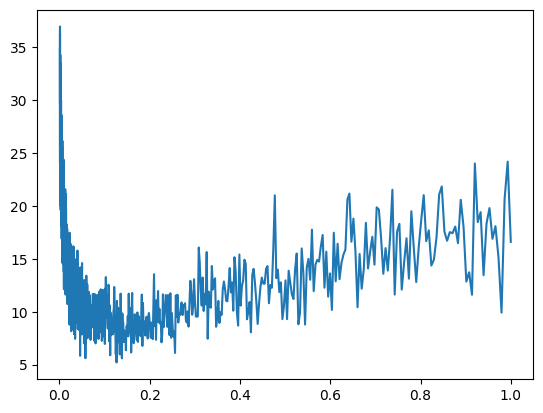

In [ ]:
plt.plot(lri, lossi)

## First real training run: block 4, 80/10/10 split, step decay

Parameters are re-initialised with `W1` of shape 40 × 300 (4 characters × 10 dims). `lr` is the argmin from the sweep (≈ 0.1–0.2), halved every 25k steps over 200k steps, with mini-batches of 64. This time `words` **is** shuffled before splitting.

In [ ]:
g = torch.Generator()
g = g.manual_seed(2147483647)
C = torch.randn((27, 10), generator = g)
W1 = torch.randn((40, 300), generator = g)
b1 = torch.randn(300, generator = g)
W2 = torch.randn((300, 27), generator = g)
b2 = torch.randn(27, generator = g)
parameters = [C, W1,b1,W2, b2]

In [ ]:
import random
def build_dataset(words):
  block_size = 4
  X, Y = [], []
  for w in words:
    #print(w)
    context = [0]*block_size
    for ch in w+'.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix]

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  return X, Y

random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))
Xtr, Ytr = build_dataset(words[:n1])
Xval, Yval = build_dataset(words[n1:n2])
Xtest, Ytest = build_dataset(words[:n2])

In [ ]:
lri = torch.tensor(lri)
lossi = torch.tensor(lossi)
lr = lri[torch.argmin(lossi)].item()

# Ensure all parameters require gradients before starting the training loop
for p in parameters:
  p.requires_grad = True

for i in range(200000):
  #minibatch for faster updates
  ix = torch.randint(0, Xtr.shape[0], (64, ))
  #forward pass
  emb = C[Xtr[ix]]
  h = torch.tanh(emb.view(-1, 40)@W1+b1)
  logits = h@W2 + b2
  #counts = logits.exp()
  #prob = counts/counts.sum(1, keepdims=True)
  #loss = -prob[torch.arange(32), Y].log().mean()
  loss = F.cross_entropy(logits, Ytr[ix])  #it does the same thing as above 3 lines
  #print(loss.item())
  #backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  for p in parameters:
    p.data+=-lr*p.grad


  if i%25000==0:
    print(loss)
    lr/=2

tensor(35.1595, grad_fn=<NllLossBackward0>)
tensor(2.2174, grad_fn=<NllLossBackward0>)
tensor(2.4432, grad_fn=<NllLossBackward0>)
tensor(2.1150, grad_fn=<NllLossBackward0>)
tensor(2.3051, grad_fn=<NllLossBackward0>)
tensor(2.3183, grad_fn=<NllLossBackward0>)
tensor(1.9644, grad_fn=<NllLossBackward0>)
tensor(2.2812, grad_fn=<NllLossBackward0>)


> ⚠️ Two evaluation bugs in the next cells:
> 1. `Xtest, Ytest = build_dataset(words[:n2])` should be `words[n2:]`. As written, the "test" set is train + val.
> 2. Both evaluation cells reuse `ix`, the indices of the **last training mini-batch** (64 rows). Since `Xtest` starts with exactly the same rows as `Xtr`, `Xtest[ix]` and `Xtr[ix]` are identical. That is why both cells print **2.0233**.
>
> To evaluate properly, run the model on the full `Xval` / `Xtest` tensors under `torch.no_grad()`.

In [ ]:
emb = C[Xtr[ix]]
h = torch.tanh(emb.view(-1, 40)@W1+b1)
logits = h@W2 + b2
#counts = logits.exp()
#prob = counts/counts.sum(1, keepdims=True)
#loss = -prob[torch.arange(32), Y].log().mean()
loss = F.cross_entropy(logits, Ytr[ix])
loss

tensor(2.0233, grad_fn=<NllLossBackward0>)

In [ ]:
emb = C[Xtest[ix]]
h = torch.tanh(emb.view(-1, 40)@W1+b1)
logits = h@W2 + b2
#counts = logits.exp()
#prob = counts/counts.sum(1, keepdims=True)
#loss = -prob[torch.arange(32), Y].log().mean()
loss = F.cross_entropy(logits, Ytest[ix])
loss

tensor(2.0233, grad_fn=<NllLossBackward0>)

Samples with 4 characters of context: `jerishel`, `zarshlie`, `ezelis`, `ulana`. They are clearly more name-like than the bigram samples.

In [ ]:
block_size = 4 # Corrected block_size to match model architecture (4 * 10 = 40 features for W1)

for _ in range(10): # Generate 10 examples
  out = []
  context = [0]*block_size # Initialize context for each new word
  while True:
    emb = C[torch.tensor([context])] # (1, block_size, C.shape[1])
    h = torch.tanh(emb.view(1, -1)@W1+b1) # (1, block_size * C.shape[1]) @ W1 (40, 300) -> (1, 300)
    logits = h@W2 + b2 # (1, 300) @ W2 (300, 27) -> (1, 27)
    probs = F.softmax(logits, dim=1) # (1, 27)
    ix = torch.multinomial(probs, num_samples=1, generator=g).item() # Sample one index
    context = context[1:] + [ix] # Update context for next character
    out.append(itos[ix]) # Convert index to character and append
    if ix == 0: # If we sample the special '.' token, break
      break
  print(''.join(out)) # Print the generated word

reri.
deera.
jerishel.
bried.
soan.
ydua.
yranl.
zarshlie.
ezelis.
ulana.
